# Notebook 04: tabele i rysunki

Wszystkie liczby pochodzą z jednego pliku predykcji `data/dane_z_prawdopodobienstwem.csv`, więc tabele, liczba błędów przekazana do modelu tematycznego i macierze pomyłek opisują ten sam przebieg.

Logika siedzi w `src/evaluation.py` i `src/visualization.py`; ten notebook ją wywołuje i pokazuje wyniki.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "src" / "data.py").is_file():
    if ROOT == ROOT.parent:
        raise RuntimeError(f"Nie znaleziono korzenia projektu startujac z {pathlib.Path.cwd()}")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
print("ROOT:", ROOT)

from src.evaluation import build_article_tables

ROOT: d:\ARTYKUL


## Przeliczenie

Jedno wywołanie liczy wszystko i zapisuje do `outputs/`. Uczenie punktów odniesienia TF-IDF zajmuje około 7 s; `skip_baselines=True` je pomija.

d:\ARTYKUL\venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Embeddingi zamrozonego enkodera wczytane z frozen_herbert_embeddings.npy
Błędów na teście: 3042 (accuracy 0.7625)


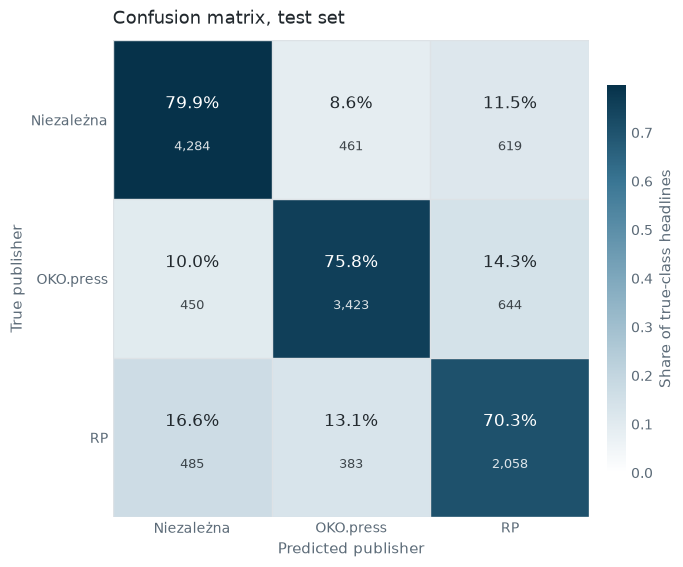

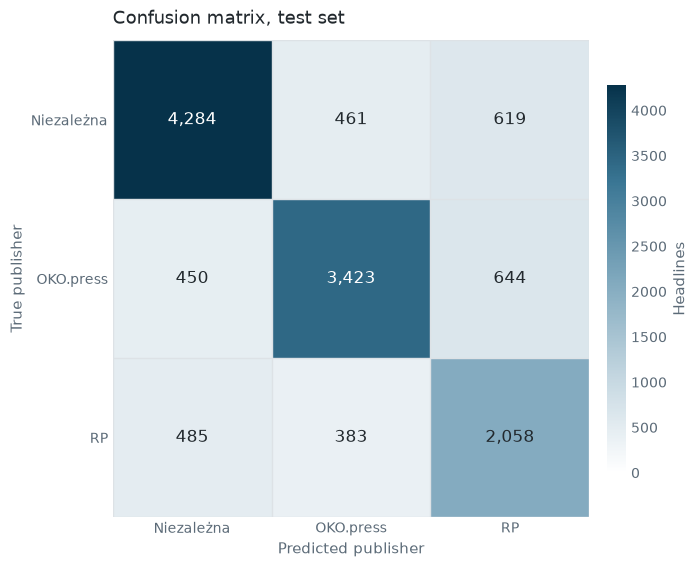

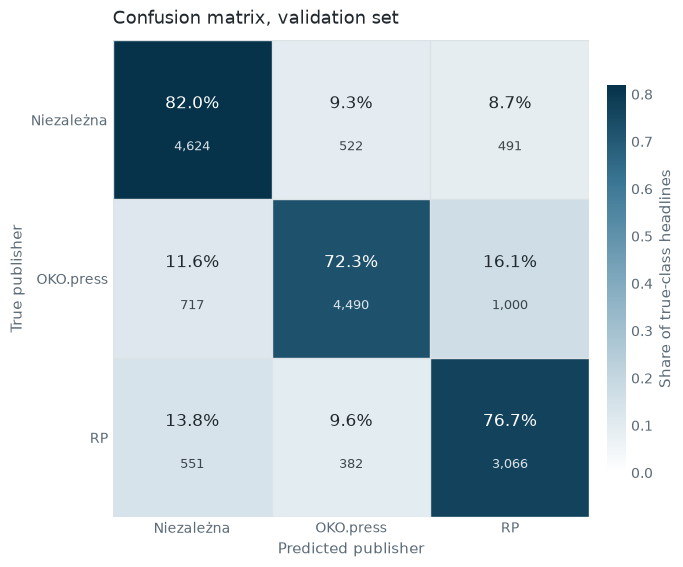

In [2]:
wyniki = build_article_tables()
print(f"Błędów na teście: {wyniki['n_errors_test']} "
      f"(accuracy {wyniki['accuracy_test']:.4f})")

## Klasyfikator na tle punktów odniesienia

Przewaga modelu kontekstowego nad TF-IDF mówi, jaka część zadania daje się rozwiązać samymi cechami leksykalnymi.

In [3]:
wyniki["baselines"].style.format({c: "{:.3f}" for c in wyniki["baselines"].columns[1:]})

,model,accuracy_valid,f1_macro_valid,accuracy_test,f1_macro_test
0,Klasa większościowa,0.356,0.175,0.419,0.197
1,TF-IDF + regresja logistyczna,0.668,0.662,0.682,0.671
2,TF-IDF + liniowy SVM,0.649,0.643,0.659,0.647
3,HerBERT (bez dostrojenia),0.695,0.688,0.704,0.688
4,HerBERT (dostrojony),0.769,0.764,0.762,0.749


In [4]:
v = wyniki["tfidf_vocab"]
if v:
    print(f"Słownik TF-IDF: {v['vocab_filtered']} termów "
          f"(bez filtrowania {v['vocab_unfiltered']})")

Słownik TF-IDF: 23775 termów (bez filtrowania 218524)


## Metryki według wydawcy

Precyzja, czułość i F1 osobno dla każdego tytułu, na zbiorze walidacyjnym i testowym.

In [5]:
wyniki["per_publisher"]

,Gazeta,Zbiór,Accuracy,Precision,Recall,F1-Score,Liczba
0,Niezależna,walidacyjny,0.7688,0.7848,0.8203,0.8022,5637
1,OKO.press,walidacyjny,,0.8324,0.7234,0.7741,6207
2,RP,walidacyjny,,0.6728,0.7667,0.7167,3999
3,Średnia ważona,walidacyjny,0.7688,0.7752,0.7688,0.7696,15843
4,Niezależna,testowy,0.7625,0.8208,0.7987,0.8096,5364
5,OKO.press,testowy,,0.8022,0.7578,0.7794,4517
6,RP,testowy,,0.6197,0.7033,0.6589,2926
7,Średnia ważona,testowy,0.7625,0.7683,0.7625,0.7645,12807


## Macierze pomyłek

Wiersz to wydawca prawdziwy, kolumna przewidywany. Pliki trafiają do `outputs/figures/`.

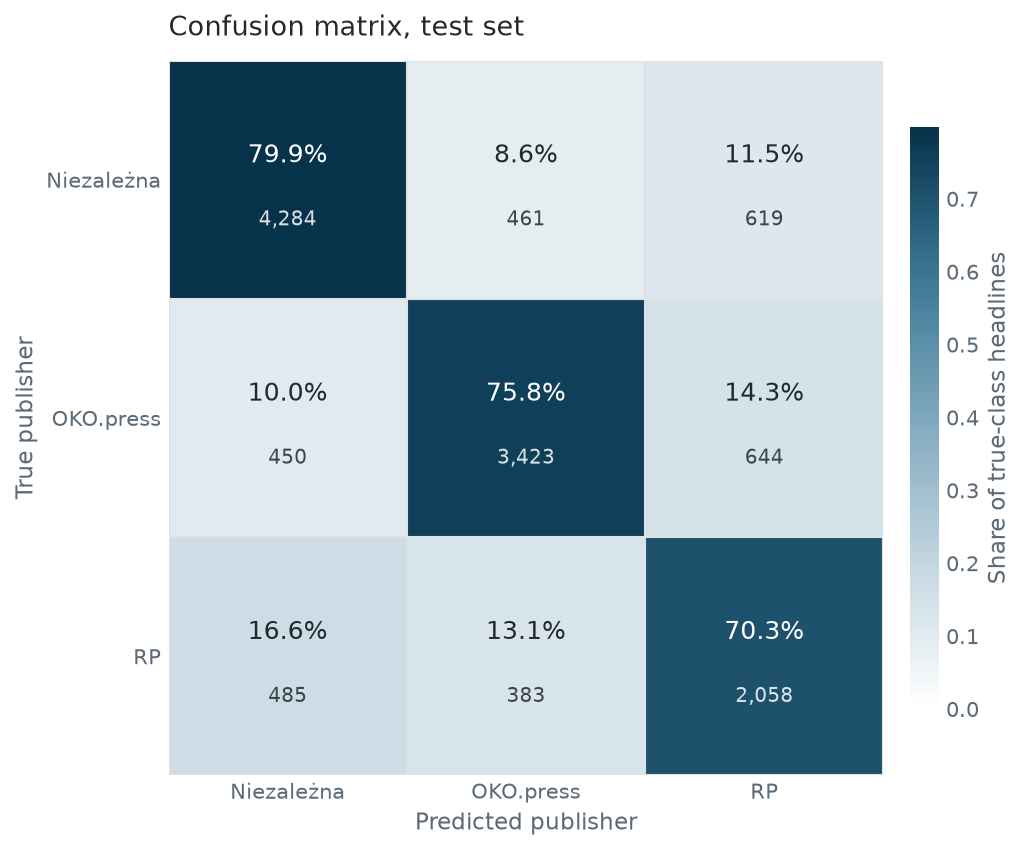

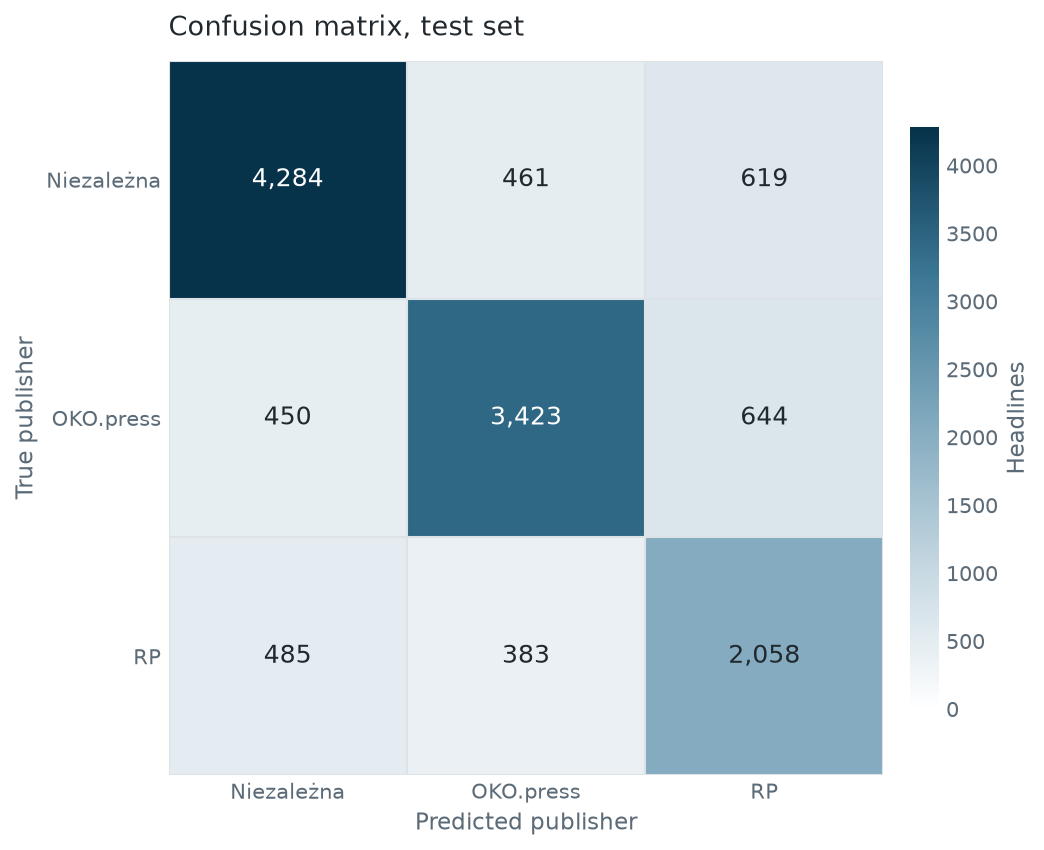

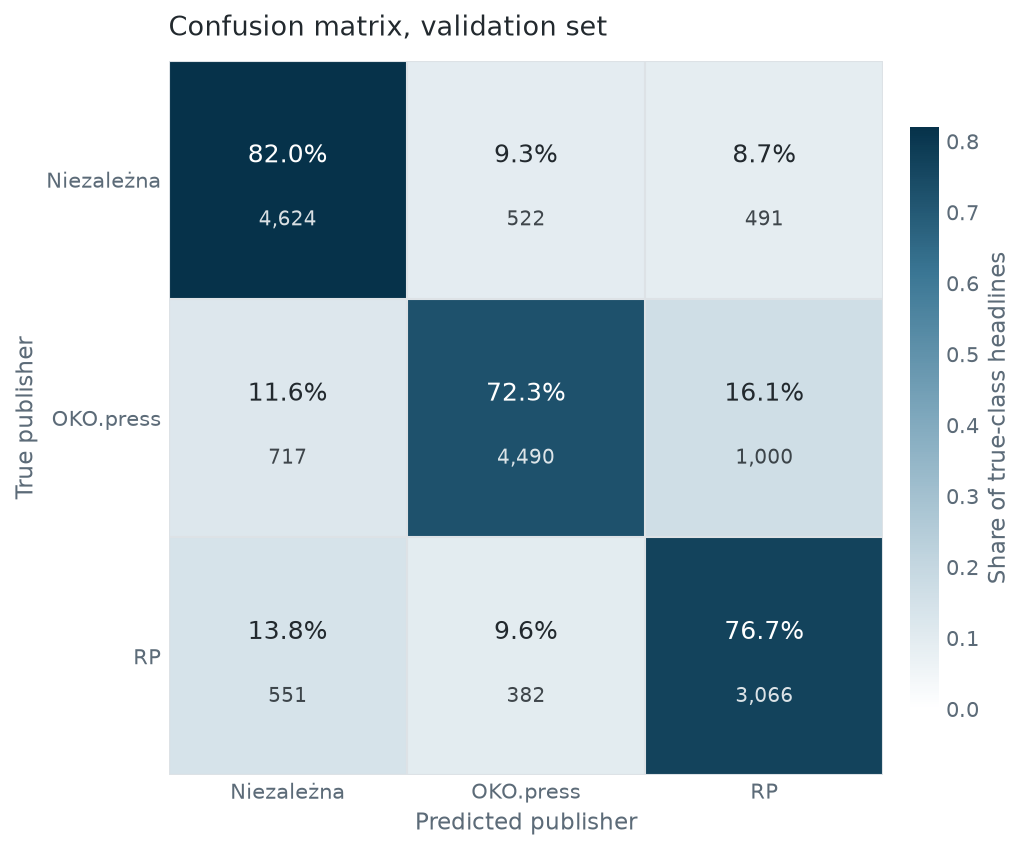

In [6]:
from IPython.display import Image, display
for p in wyniki["figures"]:
    display(Image(filename=str(p)))

## Tematy błędów

Zestawienie: czołowe terminy tematu, liczebność, rozkład wydawcy prawdziwego i przewidywanego oraz najczęstsza para pomyłki.

Tabela opisuje model tematyczny zapisany w `models/misclassified_topic_model`. Jeśli predykcje zostały przeliczone po jego zbudowaniu, trzeba go odtworzyć przez `build_misclassified_topics` z `src/topics.py`.

In [7]:
wyniki["error_topics"]

,Topic,Top terms,N,"True publisher (N / O / RP, %)","Predicted publisher (N / O / RP, %)",Dominant confusion
0,0,"tuska, jak, to, tusk, ale, a",207,42 / 35 / 23,47 / 52 / 0,N→O (42%)
1,1,"tuska, komentuje, rzeczpospolitej, to, trzasko...",129,5 / 12 / 84,95 / 0 / 5,RP→N (84%)
2,2,"pis, tusk, partnerskie, związki partnerskie, z...",121,32 / 58 / 10,0 / 16 / 84,O→RP (58%)
3,3,"usa, zełenski, ue, szczyt, europa, ukraina",118,4 / 90 / 6,53 / 8 / 39,O→N (53%)
4,4,"sondaż, najnowszy, sondażu, najnowszy sondaż, ...",103,19 / 18 / 62,61 / 9 / 30,RP→N (54%)
5,5,"czyli, rzecz w, rzecz w tym, w tym, czy, rzecz",93,29 / 8 / 63,0 / 89 / 11,RP→O (63%)
6,6,"prokuratura, wrzosek, barbary, barbary skrzype...",86,51 / 42 / 7,6 / 21 / 73,O→RP (37%)
7,7,"msz, prezydent, duda, rzecznik, usa, wątpliwości",78,18 / 26 / 56,78 / 0 / 22,RP→N (56%)
8,8,"skomentował, cpk, temat, pisze o, na temat, wy...",67,97 / 1 / 1,1 / 0 / 99,N→RP (97%)
9,9,"projekt, ustawa, ustawy, sejm, ustawę, projekt...",60,7 / 67 / 27,87 / 2 / 12,O→N (60%)
